# Capstone Project for Strategic AI Deployment


In this walkthrough, students will develop an AI-driven solution strategy tailored to a specific business problem.

**Scenario:**
Your healthcare client is struggling to predict patient readmissions. Develop an AI solution to address this issue, and prepare a proposal highlighting the business value.

**Objective:**
- Define the problem and business goals.
- Select an AI architecture and justify their choice.
- Outline a data strategy, deployment plan, and risk mitigation strategies.
- Use Hospital Readmission data to create a working model that addresses the clients problem.




### Part 1: Load the 'hospital_readmissions_data.csv' dataset from the data directory into a Pandas DataFrame.

**Task 1:**
- Load and Preprocess the dataset.
- Perform EDA to understand patterns in the dataset
- Data Preprocessing
- Split the dataset into training and testing datasets

In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,precision_score,confusion_matrix,classification_report
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler

### Part 2: Build Models to train the datasets using Machine Learning different types alogorithims
**Task:**
- Employ diverse algorithms for predicting readmission risks.

In [9]:
#IMPORTING THE DATA 
df=pd.read_csv('./data/hospital_readmissions_data.csv.txt')
df

,Patient_ID,Age,Gender,Admission_Type,Diagnosis,Num_Lab_Procedures,Num_Medications,Num_Outpatient_Visits,Num_Inpatient_Visits,Num_Emergency_Visits,Num_Diagnoses,A1C_Result,Readmitted
0,1,69,Other,Emergency,Heart Disease,33,2,4,1,1,5,NaN,Yes
1,2,32,Female,Urgent,Diabetes,81,10,4,4,1,6,NaN,No
2,3,78,Female,Urgent,Heart Disease,75,29,4,0,3,5,Normal,No
3,4,38,Male,Elective,Diabetes,77,11,2,3,4,9,NaN,Yes
4,5,41,Female,Urgent,Diabetes,50,25,3,4,1,3,NaN,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,996,21,Female,Emergency,Heart Disease,68,10,2,3,2,9,Normal,No
996,997,43,Female,Emergency,Heart Disease,61,7,0,4,0,1,Normal,No
997,998,75,Male,Urgent,Diabetes,29,13,3,1,4,8,Normal,No
998,999,46,Other,Elective,Injury,19,20,1,4,4,1,Abnormal,No


### Part 3: Evaluating Model 

**Task:**
- Analyze model performance metrics to identify the most effective algorithm.

In [12]:
df.info()
df.describe()
#PATIENT ID IS NOT NEEDED FOR OUR PREDICTION SO DROPING IT 
df=df.drop(columns=['Patient_ID'],axis=1)
df.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Age                    1000 non-null   int64 
 1   Gender                 1000 non-null   object
 2   Admission_Type         1000 non-null   object
 3   Diagnosis              1000 non-null   object
 4   Num_Lab_Procedures     1000 non-null   int64 
 5   Num_Medications        1000 non-null   int64 
 6   Num_Outpatient_Visits  1000 non-null   int64 
 7   Num_Inpatient_Visits   1000 non-null   int64 
 8   Num_Emergency_Visits   1000 non-null   int64 
 9   Num_Diagnoses          1000 non-null   int64 
 10  A1C_Result             566 non-null    object
 11  Readmitted             1000 non-null   object
dtypes: int64(7), object(5)
memory usage: 93.9+ KB


KeyError: "['Patient_ID'] not found in axis"

In [13]:
df.isnull().sum()

Age                        0
Gender                     0
Admission_Type             0
Diagnosis                  0
Num_Lab_Procedures         0
Num_Medications            0
Num_Outpatient_Visits      0
Num_Inpatient_Visits       0
Num_Emergency_Visits       0
Num_Diagnoses              0
A1C_Result               434
Readmitted                 0
dtype: int64

In [14]:
df.duplicated().sum()

0

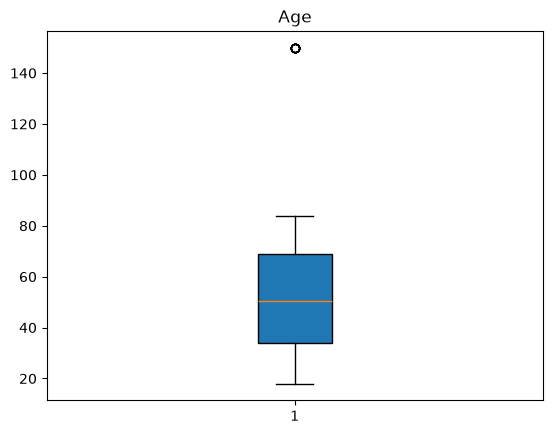

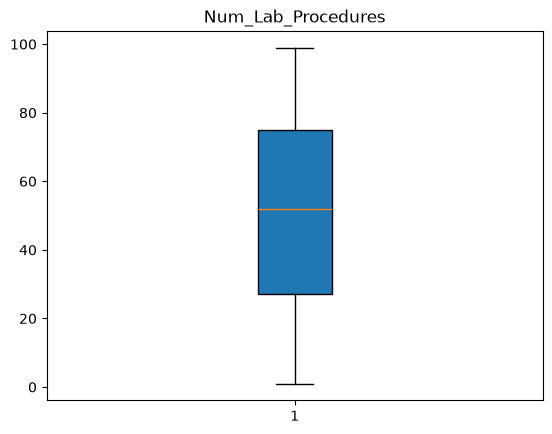

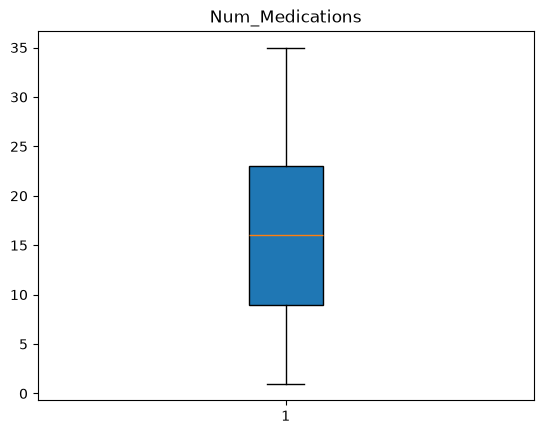

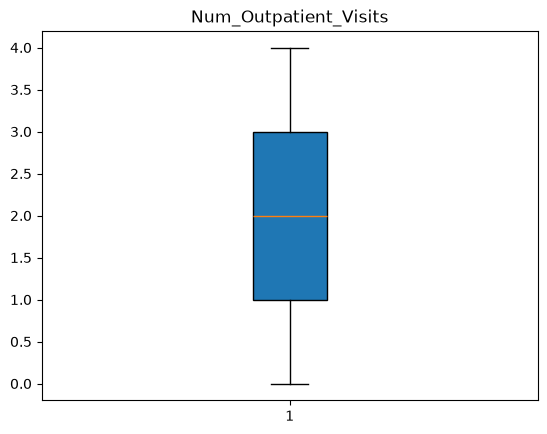

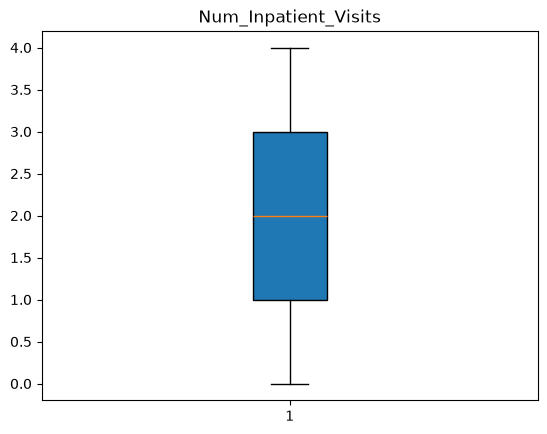

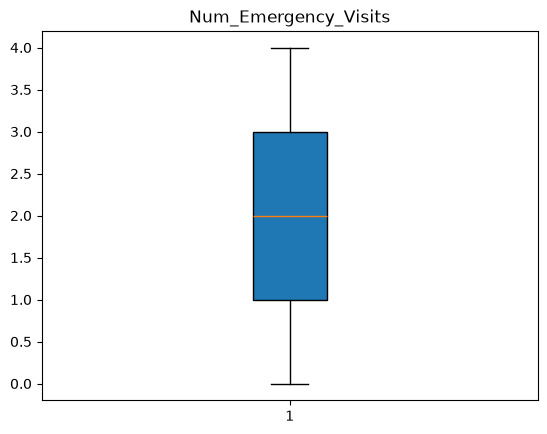

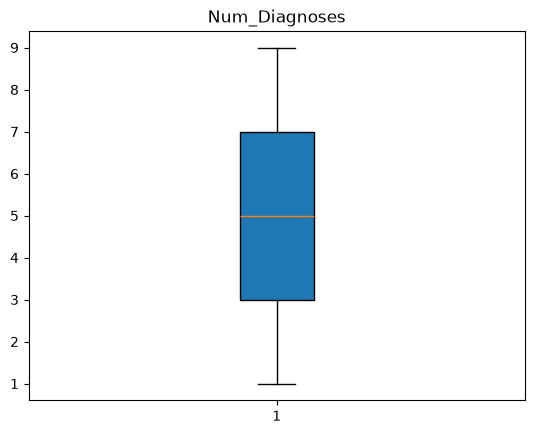

In [15]:
# TO FIND OUTLAYERS 
numeric_columns = df.select_dtypes(include=[int, float]).columns

for column in numeric_columns:
    plt.boxplot(df[column],patch_artist=True)
    plt.title(column)
    plt.show()

In [16]:
#USING IQR METHOD TO REMOVE  OUTLAYERS 
Q1=df['Age'].quantile(.25)
Q3=df['Age'].quantile(.75)
IQR=Q3-Q1
lower=Q1-1.5*IQR
upper=Q3+1.5*IQR
outlayer=(df['Age']<lower)|(df['Age']>upper)
df[~outlayer]
df=df[~outlayer]

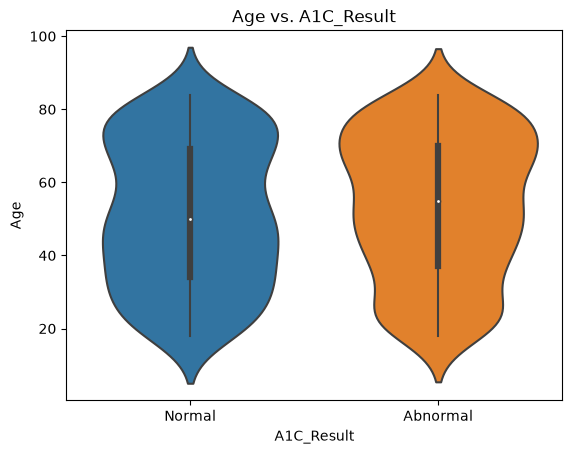

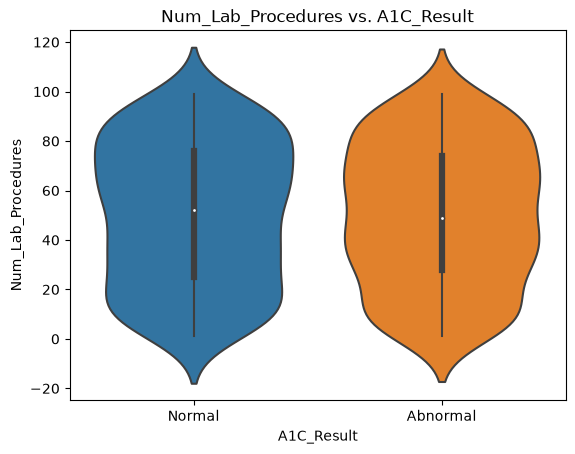

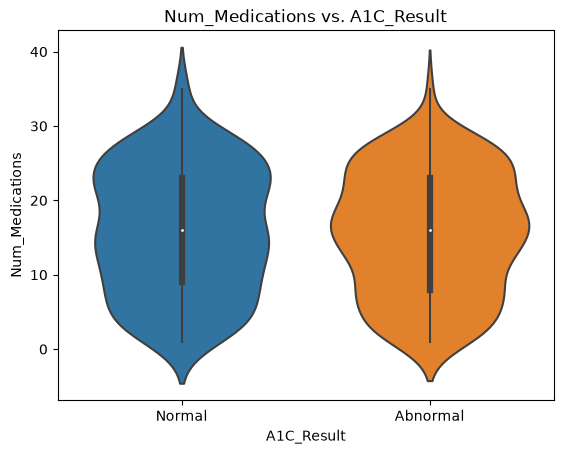

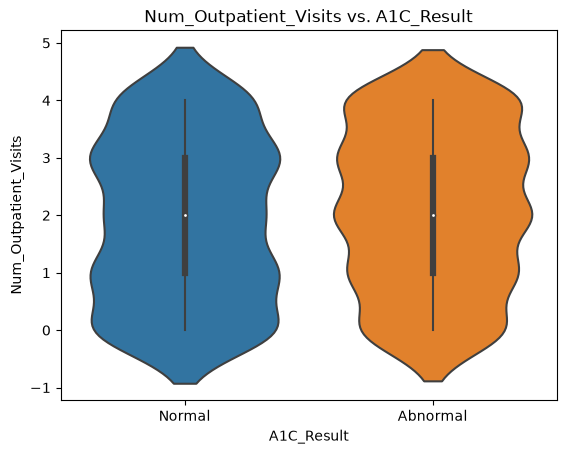

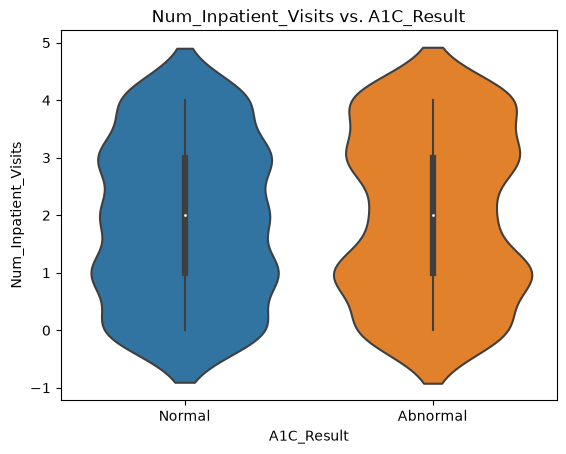

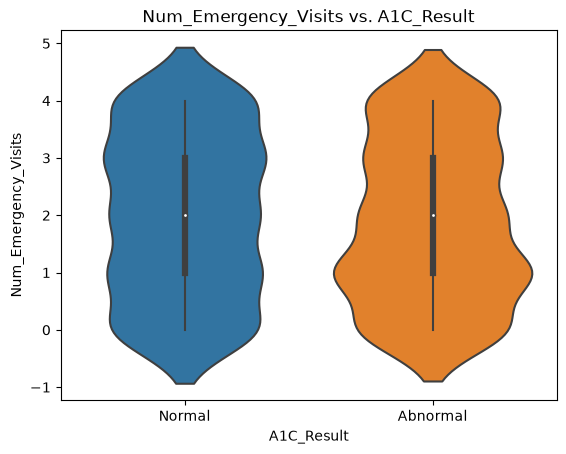

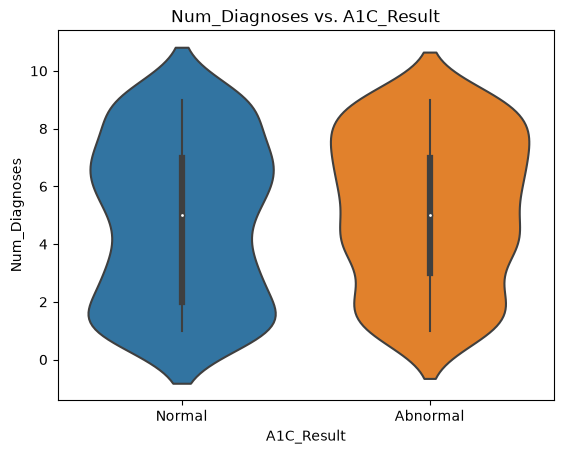

In [17]:
# DISTIBUTION OF NUMERIC VALUES DEPENDING ON THE A1C RESULT
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming df is your DataFrame
df_filtered = df.dropna(subset=['A1C_Result'])

numeric_features = ['Age', 'Num_Lab_Procedures', 'Num_Medications', 'Num_Outpatient_Visits',
                   'Num_Inpatient_Visits', 'Num_Emergency_Visits', 'Num_Diagnoses']

# plt.figure(figsize=(10, 8))
for column in numeric_features:
    sns.violinplot(x='A1C_Result', y=column, data=df_filtered)
    plt.title(f'{column} vs. A1C_Result')
    plt.show()

/tmp/ipykernel_206065/38720922.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_b['Age_Group'] = pd.cut(df_b['Age'], bins=age_bins)


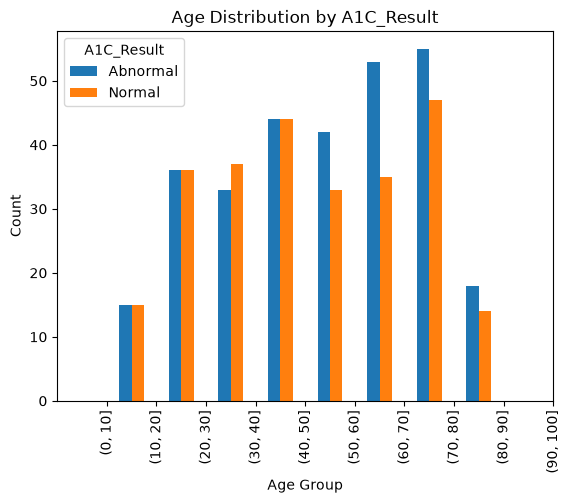

In [18]:
# A1C_RESULT has missing values it has some solution 1.droping the null values 2. using statistical method 3.using classification model 4. drpping the column
df_b=df.dropna()
# Create age bins
age_bins = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100]

# Assign age bins to a new column 'Age_Group'
df_b['Age_Group'] = pd.cut(df_b['Age'], bins=age_bins)

# Create a DataFrame for plotting
plot_data = df_b.groupby(['Age_Group', 'A1C_Result']).size().unstack()

# Plot a stacked bar plot with bars side by side
plot_data.plot(kind='bar', stacked=False, position=1.5)
plt.title('Age Distribution by A1C_Result')
plt.xlabel('Age Group')
plt.ylabel('Count')
plt.show()

/tmp/ipykernel_206065/1095359047.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_b['Num_Lab_Procedures'] = pd.cut(df_b['Num_Lab_Procedures'], bins=Num_Lab_bins)


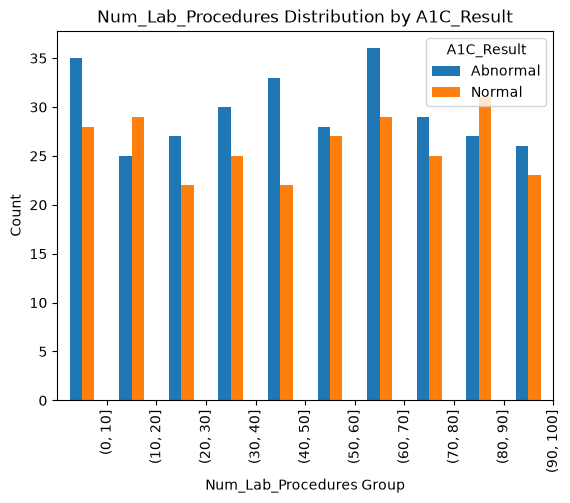

In [19]:
# Create Num_Lab_Procedures bins
Num_Lab_bins = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100]

# Assign Num_Lab_Procedures bins to a new column 'Num_Lab_Procedures'
df_b['Num_Lab_Procedures'] = pd.cut(df_b['Num_Lab_Procedures'], bins=Num_Lab_bins)

# Create a DataFrame for plotting
plot_data = df_b.groupby(['Num_Lab_Procedures', 'A1C_Result']).size().unstack()

# Plot a stacked bar plot with bars side by side
plot_data.plot(kind='bar', stacked=False, position=1.5)
plt.title('Num_Lab_Procedures Distribution by A1C_Result')
plt.xlabel('Num_Lab_Procedures Group')
plt.ylabel('Count')
plt.show()

/tmp/ipykernel_206065/541331815.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_b['Num_Medications'] = pd.cut(df_b['Num_Medications'], bins=Num_Medications_bins)


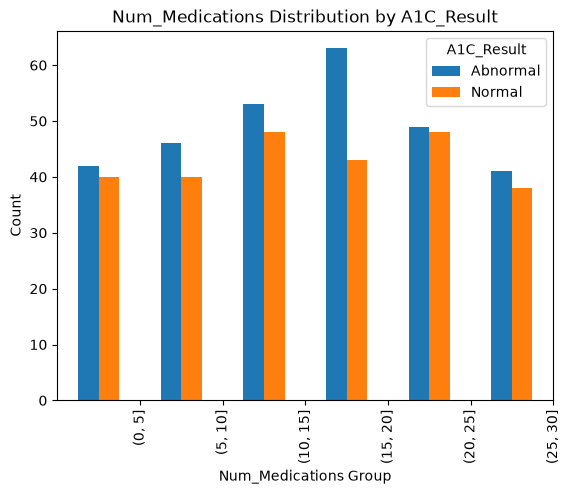

In [20]:
# Create Num_Medications bins
Num_Medications_bins = [0,5,10,15,20,25,30]

# Assign Num_Medications bins to a new column 'Num_Medications'
df_b['Num_Medications'] = pd.cut(df_b['Num_Medications'], bins=Num_Medications_bins)

# Create a DataFrame for plotting
plot_data = df_b.groupby(['Num_Medications', 'A1C_Result']).size().unstack()

# Plot a stacked bar plot with bars side by side
plot_data.plot(kind='bar', stacked=False, position=1.5)
plt.title('Num_Medications Distribution by A1C_Result')
plt.xlabel('Num_Medications Group')
plt.ylabel('Count')
plt.show()

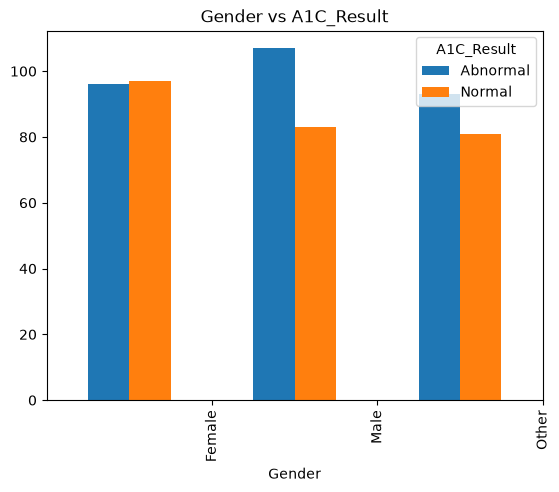

In [21]:
#GENDER AND A1C RESULT 
plto_age=df_b.groupby(['Gender','A1C_Result']).size().unstack()
plto_age.plot(kind='bar',stacked=False, position=1.5)
plt.title('Gender vs A1C_Result')
plt.show()

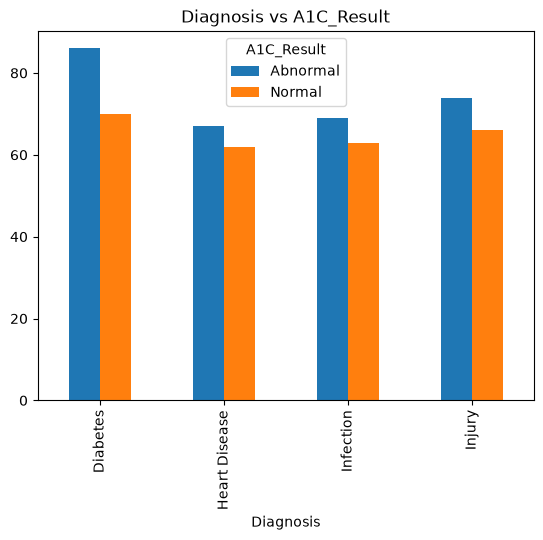

In [22]:
#DIAGNOSIS AND A1C RESULT 
plt_Diagnosis=df_b.groupby(['Diagnosis','A1C_Result']).size().unstack()
plt_Diagnosis.plot(kind='bar',stacked=False)
plt.title('Diagnosis vs A1C_Result')
plt.show()

In [23]:
ndf_A1=df.drop(columns='A1C_Result',axis=1)
ndf_A1

,Age,Gender,Admission_Type,Diagnosis,Num_Lab_Procedures,Num_Medications,Num_Outpatient_Visits,Num_Inpatient_Visits,Num_Emergency_Visits,Num_Diagnoses,Readmitted
0,69,Other,Emergency,Heart Disease,33,2,4,1,1,5,Yes
1,32,Female,Urgent,Diabetes,81,10,4,4,1,6,No
2,78,Female,Urgent,Heart Disease,75,29,4,0,3,5,No
3,38,Male,Elective,Diabetes,77,11,2,3,4,9,Yes
4,41,Female,Urgent,Diabetes,50,25,3,4,1,3,Yes
...,...,...,...,...,...,...,...,...,...,...,...
995,21,Female,Emergency,Heart Disease,68,10,2,3,2,9,No
996,43,Female,Emergency,Heart Disease,61,7,0,4,0,1,No
997,75,Male,Urgent,Diabetes,29,13,3,1,4,8,No
998,46,Other,Elective,Injury,19,20,1,4,4,1,No


In [24]:
#SEPERATING CATEGORICAL VALUES 
c=ndf_A1.select_dtypes(include='object')
# c.columns
# one_heart=['Gender', 'Admission_Type', 'Diagnosis']
# label=['Readmitted']
col=c.drop(columns=['Readmitted'],axis=1)


In [25]:
#USNIG ONE HOT ENCODING 
df_tar=c['Readmitted']
df_non_tar = c.drop(columns='Readmitted', axis=1)
df_columns = df_non_tar.columns

for i in df_columns:
    df_non_tar = pd.get_dummies(df_non_tar, columns=[i], prefix=f'Category_{i}')

df_non_tar

,Category_Gender_Female,Category_Gender_Male,Category_Gender_Other,Category_Admission_Type_Elective,Category_Admission_Type_Emergency,Category_Admission_Type_Urgent,Category_Diagnosis_Diabetes,Category_Diagnosis_Heart Disease,Category_Diagnosis_Infection,Category_Diagnosis_Injury
0,0,0,1,0,1,0,0,1,0,0
1,1,0,0,0,0,1,1,0,0,0
2,1,0,0,0,0,1,0,1,0,0
3,0,1,0,1,0,0,1,0,0,0
4,1,0,0,0,0,1,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...
995,1,0,0,0,1,0,0,1,0,0
996,1,0,0,0,1,0,0,1,0,0
997,0,1,0,0,0,1,1,0,0,0
998,0,0,1,1,0,0,0,0,0,1


In [26]:
# LABEL ENCODING FOR READMITTED COLUMN 
Lable=LabelEncoder()
c['Readmitted']=Lable.fit_transform(c['Readmitted'])
d=c['Readmitted']

In [27]:
#NOW CONCATTING THE COLUMNS INTO A SINGLE DATA FRAME 
df_en=pd.concat([df_non_tar,d],axis=1)
df_en

,Category_Gender_Female,Category_Gender_Male,Category_Gender_Other,Category_Admission_Type_Elective,Category_Admission_Type_Emergency,Category_Admission_Type_Urgent,Category_Diagnosis_Diabetes,Category_Diagnosis_Heart Disease,Category_Diagnosis_Infection,Category_Diagnosis_Injury,Readmitted
0,0,0,1,0,1,0,0,1,0,0,1
1,1,0,0,0,0,1,1,0,0,0,0
2,1,0,0,0,0,1,0,1,0,0,0
3,0,1,0,1,0,0,1,0,0,0,1
4,1,0,0,0,0,1,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...
995,1,0,0,0,1,0,0,1,0,0,0
996,1,0,0,0,1,0,0,1,0,0,0
997,0,1,0,0,0,1,1,0,0,0,0
998,0,0,1,1,0,0,0,0,0,1,0


In [28]:
e=df['A1C_Result']
df_en=pd.concat([df_en,e],axis=1)
df_en

,Category_Gender_Female,Category_Gender_Male,Category_Gender_Other,Category_Admission_Type_Elective,Category_Admission_Type_Emergency,Category_Admission_Type_Urgent,Category_Diagnosis_Diabetes,Category_Diagnosis_Heart Disease,Category_Diagnosis_Infection,Category_Diagnosis_Injury,Readmitted,A1C_Result
0,0,0,1,0,1,0,0,1,0,0,1,NaN
1,1,0,0,0,0,1,1,0,0,0,0,NaN
2,1,0,0,0,0,1,0,1,0,0,0,Normal
3,0,1,0,1,0,0,1,0,0,0,1,NaN
4,1,0,0,0,0,1,1,0,0,0,1,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
995,1,0,0,0,1,0,0,1,0,0,0,Normal
996,1,0,0,0,1,0,0,1,0,0,0,Normal
997,0,1,0,0,0,1,1,0,0,0,0,Normal
998,0,0,1,1,0,0,0,0,0,1,0,Abnormal


In [29]:
df_num=df.select_dtypes(include=[int,float])
df_en=pd.concat([df_num,df_en],axis=1)

In [30]:
df1=df_en.dropna()
df1

,Age,Num_Lab_Procedures,Num_Medications,Num_Outpatient_Visits,Num_Inpatient_Visits,Num_Emergency_Visits,Num_Diagnoses,Category_Gender_Female,Category_Gender_Male,Category_Gender_Other,Category_Admission_Type_Elective,Category_Admission_Type_Emergency,Category_Admission_Type_Urgent,Category_Diagnosis_Diabetes,Category_Diagnosis_Heart Disease,Category_Diagnosis_Infection,Category_Diagnosis_Injury,Readmitted,A1C_Result
2,78,75,29,4,0,3,5,1,0,0,0,0,1,0,1,0,0,0,Normal
7,70,28,19,4,0,3,7,1,0,0,1,0,0,0,1,0,0,1,Normal
8,19,70,23,1,2,4,6,0,1,0,0,0,1,0,0,1,0,0,Normal
9,47,41,24,4,0,0,3,0,1,0,0,1,0,0,0,0,1,0,Abnormal
11,19,68,14,2,4,2,5,1,0,0,0,1,0,0,0,0,1,0,Abnormal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,21,68,10,2,3,2,9,1,0,0,0,1,0,0,1,0,0,0,Normal
996,43,61,7,0,4,0,1,1,0,0,0,1,0,0,1,0,0,0,Normal
997,75,29,13,3,1,4,8,0,1,0,0,0,1,1,0,0,0,0,Normal
998,46,19,20,1,4,4,1,0,0,1,1,0,0,0,0,0,1,0,Abnormal


In [31]:
df1['A1C_Result']=Lable.fit_transform(df1['A1C_Result'])
df1.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 557 entries, 2 to 999
Data columns (total 19 columns):
 #   Column                             Non-Null Count  Dtype
---  ------                             --------------  -----
 0   Age                                557 non-null    int64
 1   Num_Lab_Procedures                 557 non-null    int64
 2   Num_Medications                    557 non-null    int64
 3   Num_Outpatient_Visits              557 non-null    int64
 4   Num_Inpatient_Visits               557 non-null    int64
 5   Num_Emergency_Visits               557 non-null    int64
 6   Num_Diagnoses                      557 non-null    int64
 7   Category_Gender_Female             557 non-null    uint8
 8   Category_Gender_Male               557 non-null    uint8
 9   Category_Gender_Other              557 non-null    uint8
 10  Category_Admission_Type_Elective   557 non-null    uint8
 11  Category_Admission_Type_Emergency  557 non-null    uint8
 12  Category_Admission_Typ

/tmp/ipykernel_206065/348272495.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1['A1C_Result']=Lable.fit_transform(df1['A1C_Result'])


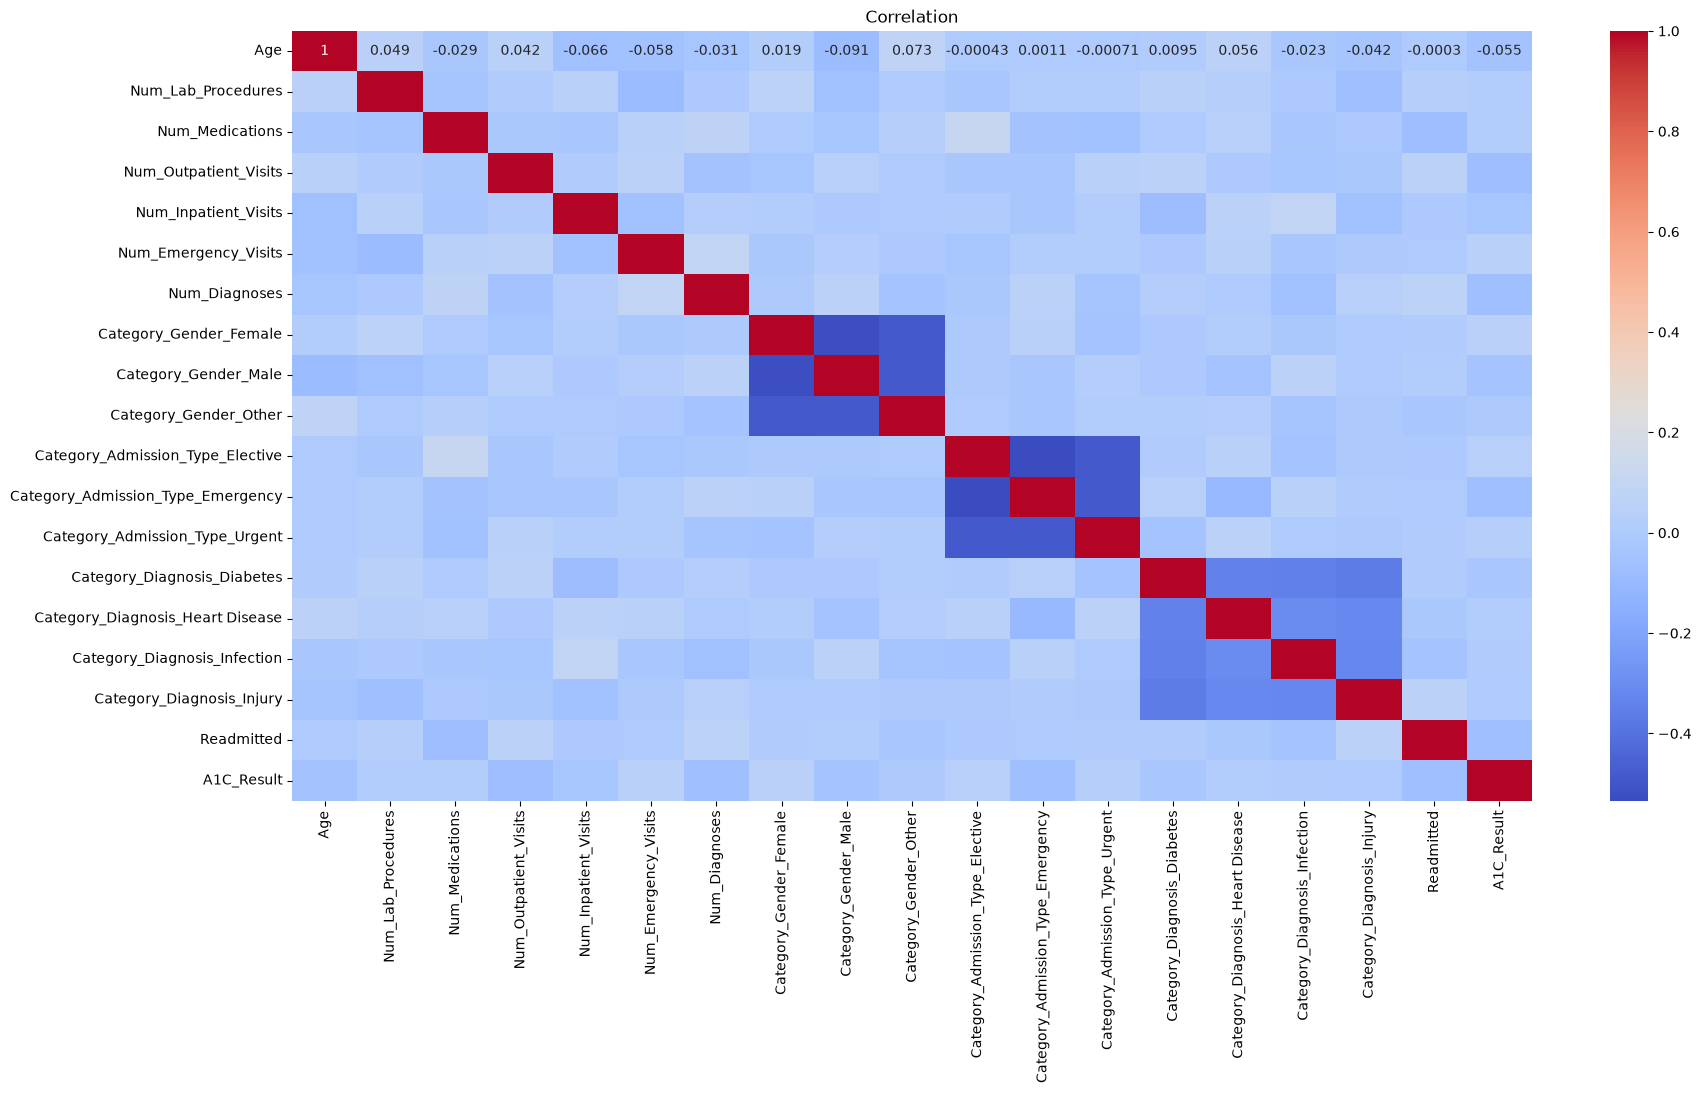

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'df1' is your DataFrame
corr = df1.corr()

# Create a figure with a specific size
plt.figure(figsize=(20,10))

# Create a heatmap
sns.heatmap(corr, cmap='coolwarm', annot=True)

# Set the title
plt.title('Correlation')

# Show the plot
plt.show()

In [33]:
import pandas as pd

# Assuming your DataFrame is named df1
# Extract the target variable
target_variable = df1['A1C_Result']

# Calculate the correlation between the target variable and other columns
correlations = df1.drop(columns=['A1C_Result']).corrwith(target_variable)

# Display the correlations in descending order
sorted_correlations = correlations.abs().sort_values(ascending=False)
print("Correlations with A1C_Result:")
print(sorted_correlations)

Correlations with A1C_Result:
Num_Outpatient_Visits                0.073522
Num_Diagnoses                        0.069942
Category_Admission_Type_Emergency    0.067245
Readmitted                           0.067127
Age                                  0.054548
Category_Gender_Female               0.049626
Category_Gender_Male                 0.045765
Num_Emergency_Visits                 0.043077
Category_Admission_Type_Elective     0.038476
Num_Inpatient_Visits                 0.036542
Category_Admission_Type_Urgent       0.029814
Category_Diagnosis_Diabetes          0.024828
Num_Medications                      0.017884
Category_Diagnosis_Heart Disease     0.013244
Num_Lab_Procedures                   0.011182
Category_Diagnosis_Infection         0.009706
Category_Gender_Other                0.004139
Category_Diagnosis_Injury            0.003306
dtype: float64


In [34]:
scaler=MinMaxScaler()
df1['Age'] = scaler.fit_transform(df1[['Age']])
df1['Age']

/tmp/ipykernel_206065/2081219995.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1['Age'] = scaler.fit_transform(df1[['Age']])


2      0.909091
7      0.787879
8      0.015152
9      0.439394
11     0.015152
         ...   
995    0.045455
996    0.378788
997    0.863636
998    0.424242
999    0.545455
Name: Age, Length: 557, dtype: float64

In [35]:
df1['Num_Lab_Procedures'] = scaler.fit_transform(df1[['Num_Lab_Procedures']])
df1['Num_Lab_Procedures'] 

/tmp/ipykernel_206065/3050529747.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1['Num_Lab_Procedures'] = scaler.fit_transform(df1[['Num_Lab_Procedures']])


2      0.755102
7      0.275510
8      0.704082
9      0.408163
11     0.683673
         ...   
995    0.683673
996    0.612245
997    0.285714
998    0.183673
999    0.428571
Name: Num_Lab_Procedures, Length: 557, dtype: float64

In [36]:
df1['Num_Medications'] = scaler.fit_transform(df1[['Num_Medications']])
df1['Num_Medications']

/tmp/ipykernel_206065/3535480959.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1['Num_Medications'] = scaler.fit_transform(df1[['Num_Medications']])


2      0.823529
7      0.529412
8      0.647059
9      0.676471
11     0.382353
         ...   
995    0.264706
996    0.176471
997    0.352941
998    0.558824
999    0.794118
Name: Num_Medications, Length: 557, dtype: float64

In [37]:
x=df1.drop(columns=['A1C_Result','Category_Admission_Type_Urgent','Num_Inpatient_Visits','Age','Category_Admission_Type_Elective','Category_Diagnosis_Diabetes','Category_Admission_Type_Emergency','Num_Emergency_Visits'],axis=1)
y=df1['A1C_Result']

In [38]:
# x_test,x_train,y_test,y_train=train_test_split(x,y,test_size=0.1,random_state=0),58

x_train1, x_test1, y_train1, y_test1 = train_test_split(x, y, test_size=0.1, random_state=72)
model = LogisticRegression(random_state=58)
model.fit(x_train1, y_train1)
y_pred1 = model.predict(x_test1)

accuracy1 = accuracy_score(y_test1, y_pred1)
classification_rep1=classification_report(y_test1, y_pred1)


print(" Accuracy in LOG_REG:", accuracy1)
print(f'Classification Report:\n{classification_rep1}')

 Accuracy in LOG_REG: 0.5357142857142857
Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.54      0.62        39
           1       0.33      0.53      0.41        17

    accuracy                           0.54        56
   macro avg       0.53      0.53      0.51        56
weighted avg       0.61      0.54      0.55        56



In [39]:
# # Decesion tree classification
x_train2, x_test2, y_train2, y_test2 = train_test_split(x, y, test_size=0.1, random_state=72)
model2 = DecisionTreeClassifier(random_state=72)
model2.fit(x_train2, y_train2)
y_pred2 = model2.predict(x_test2)

accuracy2 = accuracy_score(y_test2, y_pred2)
classification_rep2=classification_report(y_test2, y_pred2)


print("Accuracy in DEC_TREE:", accuracy2)
print(f'Classification Report:\n{classification_rep2}')


Accuracy in DEC_TREE: 0.5892857142857143
Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.67      0.69        39
           1       0.35      0.41      0.38        17

    accuracy                           0.59        56
   macro avg       0.54      0.54      0.54        56
weighted avg       0.61      0.59      0.60        56



In [40]:

x_train3,x_test3,y_train3,y_test3=train_test_split(x,y, test_size=0.1,random_state=72)
model3=SVC(random_state=72)
model3.fit(x_train3,y_train3)
y_pred3=model3.predict(x_test3)

accuracy3=accuracy_score(y_test3,y_pred3)
classification_rep3=classification_report(y_test3,y_pred3)

print("Accuracy in SVM:", accuracy3)
print(f'Classification Report:\n{classification_rep3}')

Accuracy in SVM: 0.6607142857142857
Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.79      0.77        39
           1       0.43      0.35      0.39        17

    accuracy                           0.66        56
   macro avg       0.58      0.57      0.58        56
weighted avg       0.64      0.66      0.65        56



In [41]:
x_train4,x_test4,y_train4,y_test4=train_test_split(x,y, test_size=0.1,random_state=72)
model4=RandomForestClassifier(random_state=72)
model4.fit(x_train4,y_train4)
y_pred4=model4.predict(x_test4)

accuracy4=accuracy_score(y_test4,y_pred4)
classification_rep4=classification_report(y_test4,y_pred4)

print("Accuracy in RF:", accuracy4)
print(f'Classification Report:\n{classification_rep4}')


Accuracy in RF: 0.5535714285714286
Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.62      0.66        39
           1       0.32      0.41      0.36        17

    accuracy                           0.55        56
   macro avg       0.51      0.51      0.51        56
weighted avg       0.59      0.55      0.57        56

